# 1992 — REINFORCE: Policy Gradients (Williams)

**Paper:** Ronald J. Williams, *"Simple Statistical Gradient-Following Algorithms for Connectionist Reinforcement Learning"*, Machine Learning 8 (1992). Policy-gradient theorem: Sutton, McAllester, Singh & Mansour (2000).

DQN (notebook 20) learns *values* and acts greedily on them. REINFORCE learns the **policy** $\pi_\theta(a\mid s)$ directly, by gradient ascent on expected return $J(\theta) = \mathbb E_{\tau\sim\pi_\theta}[R(\tau)]$. The return is not differentiable (it comes from the environment), but its expectation's gradient is, thanks to the **log-derivative trick**:

$$\nabla_\theta J = \mathbb E_\tau\Big[\sum_t \nabla_\theta \log \pi_\theta(a_t\mid s_t)\,\big(G_t - b(s_t)\big)\Big]$$

- Sample actions, then make the ones that were followed by high return $G_t$ more likely.
- $b$ is a **baseline**. Subtracting it leaves the gradient unbiased (since $\mathbb E[\nabla\log\pi]=0$) but can greatly reduce its variance.

This one equation is the root of PPO (notebook 38), RLHF (notebook 57) and GRPO (notebook 69). GRPO's "group-relative advantage" is exactly REINFORCE with the group's mean reward as the baseline.

![Diagram: REINFORCE (Williams, 1992)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/12_1992_reinforce_policy_gradient.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
device = torch.device("cpu")      # tiny networks, one step at a time: CPU is faster here
torch.set_num_threads(1)

PyTorch 2.15.0 | device: mps


## The estimator is unbiased; the baseline only changes its variance
A 3-armed bandit with a softmax policy, where the exact gradient is available in closed form. Each sample gives $\nabla\log\pi(a)\,(r - b)$; averaging many samples should match the true gradient, with or without a baseline.

In [2]:
true_means = torch.tensor([1.0, 2.0, 1.5]); noise = 1.0
logits = torch.tensor([0.2, -0.1, 0.0], requires_grad=True)
p = F.softmax(logits, 0)
exact = torch.autograd.grad((p * true_means).sum(), logits)[0]          # ∇ E[r] = ∇ Σ π(a) μ_a

def sample_grads(n, baseline):
    a = torch.multinomial(p.detach(), n, replacement=True)
    r = true_means[a] + noise * torch.randn(n)
    onehot = F.one_hot(a, 3).float()
    glogp = onehot - p.detach()                                         # ∇_logits log softmax(a)
    return glogp * (r - baseline)[:, None]

torch.manual_seed(0)
for name, b in [("no baseline", 0.0), ("baseline = E[r]", (p * true_means).sum().item())]:
    g = sample_grads(200_000, b)
    print(f"{name:16s} mean {g.mean(0).numpy().round(3)}  (exact {exact.numpy().round(3)})   per-sample variance {g.var(0).sum():.2f}")

no baseline      mean [-0.176  0.161  0.015]  (exact [-0.176  0.159  0.016])   per-sample variance 2.21
baseline = E[r]  mean [-0.177  0.161  0.016]  (exact [-0.176  0.159  0.016])   per-sample variance 0.72


## CartPole with REINFORCE
Same CartPole physics as notebook 20. Each update samples a batch of episodes, computes the discounted reward-to-go $G_t$, and takes one gradient step. Three variants:

1. **Total return** $R(\tau)$ for every step (Williams' simplest form)
2. **Reward-to-go** $G_t$: an action cannot affect rewards that came before it, so drop them
3. Reward-to-go **minus a baseline**: here a learned value network $V_\phi(s)$, so the weight $G_t - V_\phi(s_t)$ is an *advantage*

In [3]:
class CartPole:
    """Classic cart-pole (Barto, Sutton & Anderson 1983), same constants as Gym's CartPole-v1."""
    g, m_cart, m_pole, half_len, force, dt = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    def __init__(self, seed=0): self.rng = np.random.default_rng(seed)
    def reset(self):
        self.s = self.rng.uniform(-0.05, 0.05, 4); self.t = 0; return self.s.astype(np.float32)
    def step(self, action):
        x, x_dot, th, th_dot = self.s
        f = self.force if action == 1 else -self.force
        total, pml = self.m_cart + self.m_pole, self.m_pole * self.half_len
        tmp = (f + pml * th_dot ** 2 * math.sin(th)) / total
        th_acc = (self.g * math.sin(th) - math.cos(th) * tmp) / (self.half_len * (4 / 3 - self.m_pole * math.cos(th) ** 2 / total))
        x_acc = tmp - pml * th_acc * math.cos(th) / total
        self.s = np.array([x + self.dt * x_dot, x_dot + self.dt * x_acc, th + self.dt * th_dot, th_dot + self.dt * th_acc])
        self.t += 1
        failed = abs(self.s[0]) > 2.4 or abs(self.s[2]) > 12 * math.pi / 180
        return self.s.astype(np.float32), 1.0, failed or self.t >= 500

def rollout(env, policy):
    S, A, R = [], [], []
    s, done = env.reset(), False
    while not done:
        with torch.no_grad(): a = torch.multinomial(F.softmax(policy(torch.from_numpy(s)), -1), 1).item()
        s2, r, done = env.step(a); S.append(s); A.append(a); R.append(r); s = s2
    return np.array(S), np.array(A), np.array(R, dtype=np.float32)

def reward_to_go(R, gamma):
    G, run = np.zeros_like(R), 0.0
    for t in reversed(range(len(R))): run = R[t] + gamma * run; G[t] = run
    return G

def reinforce(variant, updates=120, batch=8, gamma=0.99, seed=0):
    seed_everything(seed); env = CartPole(seed)
    pi = nn.Sequential(nn.Linear(4, 64), nn.Tanh(), nn.Linear(64, 2))
    V = nn.Sequential(nn.Linear(4, 64), nn.Tanh(), nn.Linear(64, 1))
    opt, opt_v = torch.optim.Adam(pi.parameters(), lr=1e-2), torch.optim.Adam(V.parameters(), lr=1e-2)
    curve = []
    for u in range(updates):
        eps = [rollout(env, pi) for _ in range(batch)]
        S = torch.tensor(np.concatenate([e[0] for e in eps])); A = torch.tensor(np.concatenate([e[1] for e in eps]))
        if variant == "total return":
            W = np.concatenate([np.full(len(e[2]), reward_to_go(e[2], gamma)[0]) for e in eps])
        else:
            W = np.concatenate([reward_to_go(e[2], gamma) for e in eps])
        W = torch.tensor(W)
        if variant == "reward-to-go - V(s)":
            G = W.clone(); W = G - V(S).squeeze(-1).detach()
            for _ in range(5):
                lv = F.mse_loss(V(S).squeeze(-1), G); opt_v.zero_grad(); lv.backward(); opt_v.step()
        W = W / (W.std() + 1e-8)                                         # scale only; keeps the sign of each weight
        logp = F.log_softmax(pi(S), -1).gather(1, A[:, None]).squeeze(1)
        loss = -(logp * W).sum() / batch                                 # the REINFORCE surrogate
        opt.zero_grad(); loss.backward(); opt.step()
        curve.append(np.mean([len(e[2]) for e in eps]))
    return curve

In [4]:
variants = ["total return", "reward-to-go", "reward-to-go - V(s)"]
curves = {v: [reinforce(v, seed=s) for s in range(3)] for v in variants}
for v in variants:
    c = np.array(curves[v]); print(f"{v:22s} mean episode length over the last 20 updates: {c[:, -20:].mean():6.1f}  (max 500; random policy ≈ 22)")

total return           mean episode length over the last 20 updates:   61.6  (max 500; random policy ≈ 22)
reward-to-go           mean episode length over the last 20 updates:  354.0  (max 500; random policy ≈ 22)
reward-to-go - V(s)    mean episode length over the last 20 updates:  499.1  (max 500; random policy ≈ 22)


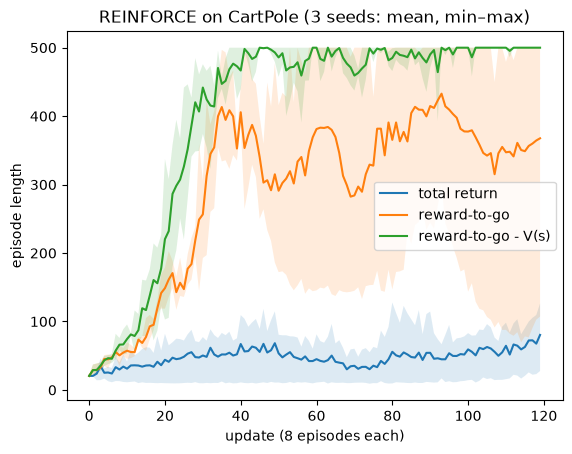

In [5]:
for v in variants:
    c = np.array(curves[v]); m = c.mean(0)
    plt.plot(m, label=v); plt.fill_between(range(len(m)), c.min(0), c.max(0), alpha=0.15)
plt.xlabel("update (8 episodes each)"); plt.ylabel("episode length"); plt.title("REINFORCE on CartPole (3 seeds: mean, min–max)"); plt.legend(); plt.show()

## Takeaways
- **Log-derivative trick:** you can follow the gradient of an expected reward without differentiating the environment. Only $\log\pi$ needs a gradient.
- **Variance is the problem**, not bias. Reward-to-go and a baseline are both free variance reductions, and the bandit check shows the baseline leaves the mean untouched.
- **Where it went:** actor-critic methods learn the baseline $V$; PPO (notebook 38) adds a trust region so each batch can be reused for several steps; RLHF (notebook 57) applies PPO to language models; GRPO (notebook 69) returns to plain REINFORCE-style advantages with the group mean as baseline and drops the value network.